# Digital Image Processing — Week 5 · Task 1

**Grup: Nmertgules ve Iliya**

OpenCV ile renk kanalı histogramları

Renkli görüntü önce gösterilir. `cv2.calcHist` renkli görüntünün kendisine uygulanır ve `channels=[i]` ile her çağrıda tek kanal seçilir: 0 = B, 1 = G, 2 = R. Görüntü griye çevrilmez.

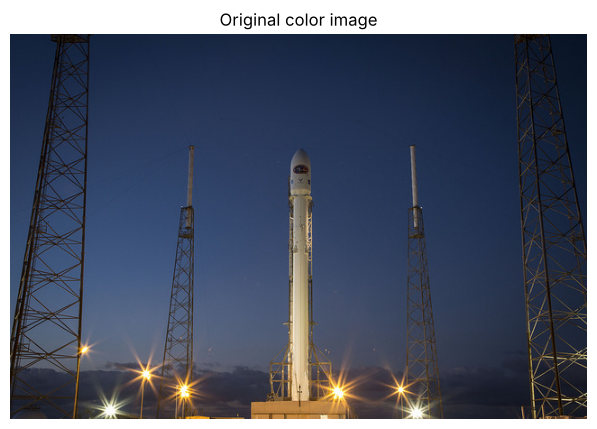

Görüntü: 640 × 427, uint8


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['svg.hashsalt'] = 'week5'  # SVG içindeki kimlikler sabit; aynı girdi aynı dosyayı üretir.

# Repo kökünü çalışılan klasörden yukarı doğru arayarak buluyoruz; böylece
# notebook hem repo kökünden hem de week5 klasöründen çalışır.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'week4' / 'assets' / 'rocket.jpg').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('week4/assets/rocket.jpg bulunamadı. Repoyu bütünüyle indirip repo içinden çalıştırın.')
IMAGE = ROOT / 'week4' / 'assets' / 'rocket.jpg'
bgr = cv2.imread(str(IMAGE), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f'Görüntü okunamadı: {IMAGE}.')
OUT = ROOT / 'week5' / 'results'
OUT.mkdir(exist_ok=True)
channels = cv2.split(bgr)  # B, G, R
names = ['Blue (B)', 'Green (G)', 'Red (R)']
colors = ['blue', 'green', 'red']
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
plt.title('Original color image')
plt.axis('off')
plt.show()
print(f'Görüntü: {bgr.shape[1]} × {bgr.shape[0]}, {bgr.dtype}')

In [2]:
# Renkli görüntünün kendisi verilir; channels=[i] her seferinde tek kanalı seçer (0=B, 1=G, 2=R).
histograms = [cv2.calcHist([bgr], [i], None, [256], [0, 256]).ravel() for i in range(3)]

# Ayrılmış kanallar üzerinden hesapla aynı sonucu vermeli.
for i, channel in enumerate(channels):
    assert np.array_equal(histograms[i], cv2.calcHist([channel], [0], None, [256], [0, 256]).ravel())

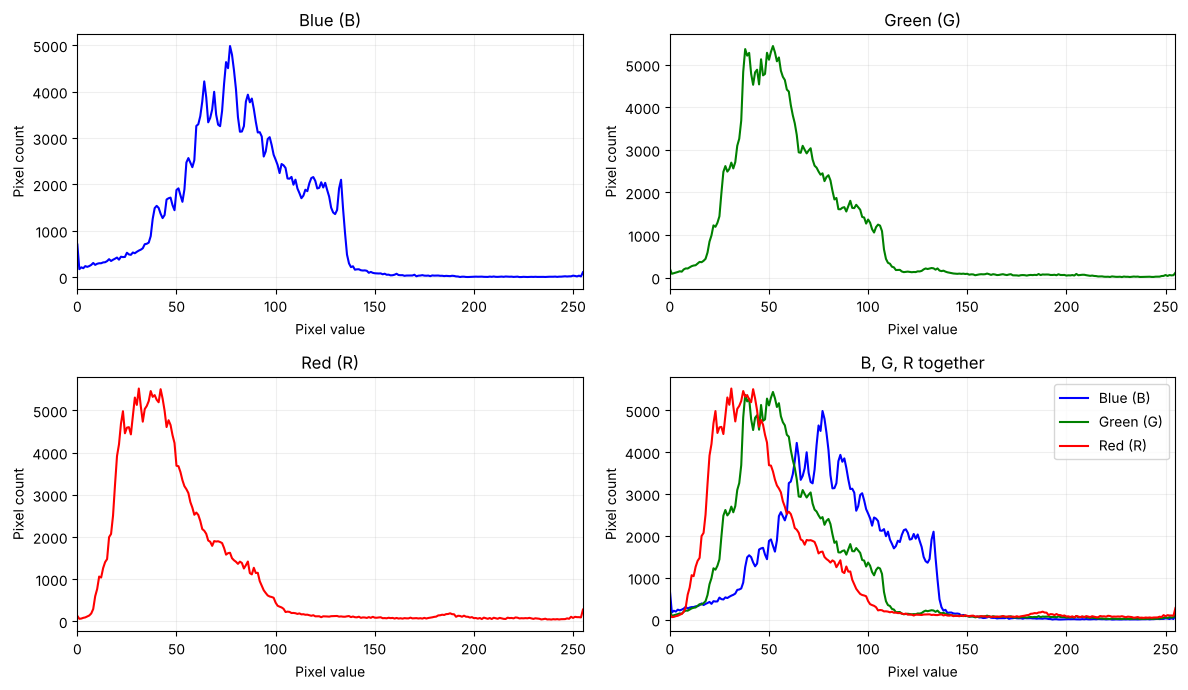

Blue (B): 256 kutu, toplam 273280 piksel
Green (G): 256 kutu, toplam 273280 piksel
Red (R): 256 kutu, toplam 273280 piksel


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, hist, name, color in zip(axes.flat, histograms, names, colors):
    ax.plot(np.arange(256), hist, color=color)
    ax.set(title=name, xlabel='Pixel value', ylabel='Pixel count', xlim=(0, 255))
    ax.grid(alpha=0.2)
# Dördüncü grafik: üç kanal aynı eksende, karşılaştırma için.
combined = axes.flat[3]
for hist, name, color in zip(histograms, names, colors):
    combined.plot(np.arange(256), hist, color=color, label=name)
combined.set(title='B, G, R together', xlabel='Pixel value', ylabel='Pixel count', xlim=(0, 255))
combined.legend()
combined.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'task1_histograms.svg', metadata={'Date': None})
plt.show()
for name, hist in zip(names, histograms):
    assert int(hist.sum()) == bgr.shape[0] * bgr.shape[1]
    print(f'{name}: {len(hist)} kutu, toplam {int(hist.sum())} piksel')